# Практическое занятие №4: Случайные сигналы, шумы и спектральная плотность мощности

## Задание 1. Генерация белого, розового и красного шума
Сгенерируйте три сигнала длительностью 2 секунды с частотой дискретизации 1000 Гц:
- Белый гауссов шум с нулевым средним и дисперсией 1.
- Розовый шум – возьмите Фурье-преобразование от белого шума, домножьте его на функцию $1/\sqrt{f}$ и возьмите обратное Фурье-преобразование, результат нормализуйте.
- красный шум – кумулятивная сумма белого шума (нормалиованная).

Постройте временные графики всех трёх сигналов. Вычислите и выведите их средние значения и дисперсии.


Шум             Среднее    Дисперсия
Белый           0.00651      0.98466
Розовый        -0.00000      1.00000
Красный         0.00000      1.00000


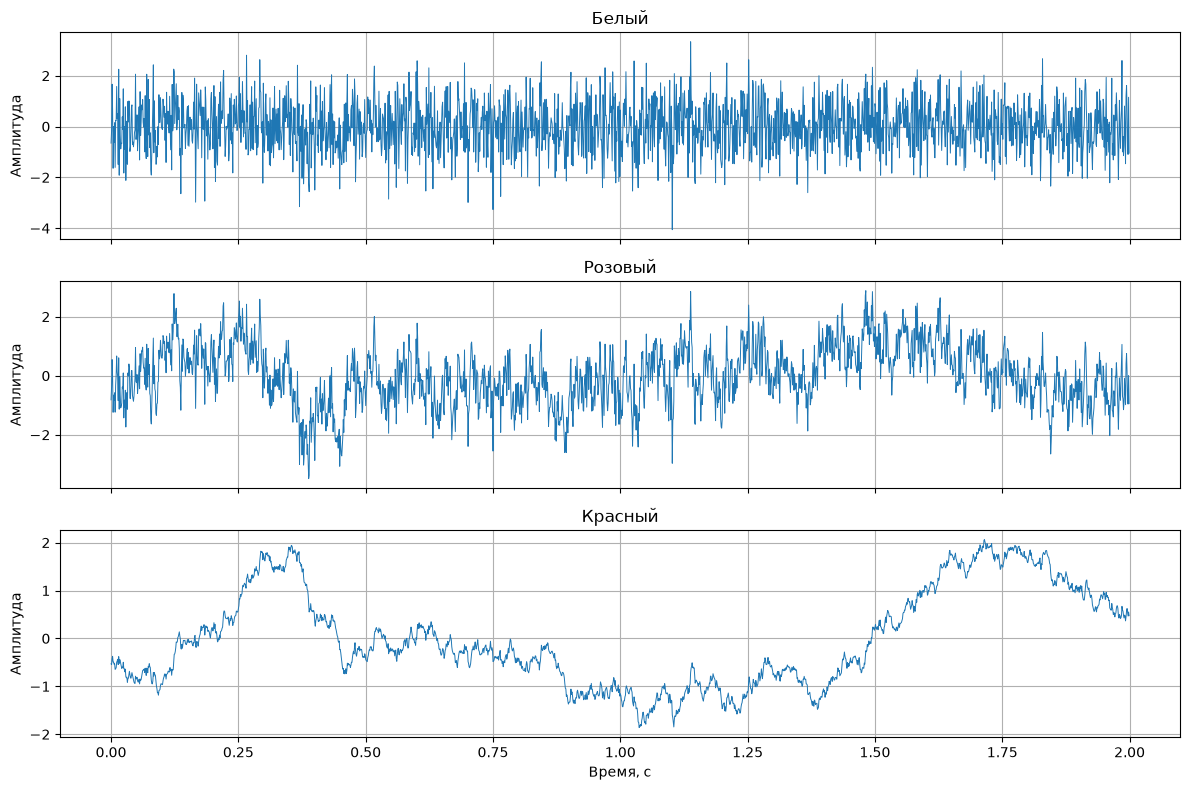

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 4)
plt.rcParams['axes.grid'] = True
rng = np.random.default_rng(4)
fs = 1000
N = 2*fs
t = np.arange(N)/fs
white = rng.standard_normal(N)
f = np.fft.rfftfreq(N, 1/fs)
weight = np.zeros_like(f)
weight[1:] = 1/np.sqrt(f[1:])  # нулевую частоту отдельно обнуляем
pink = np.fft.irfft(np.fft.rfft(white)*weight, n=N)
pink = (pink-pink.mean())/pink.std()
red = np.cumsum(white)
red = (red-red.mean())/red.std()
noises = {'Белый': white, 'Розовый': pink, 'Красный': red}
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
print(f'{"Шум":10s} {"Среднее":>12s} {"Дисперсия":>12s}')
for ax, (name, x) in zip(axes, noises.items()):
    print(f'{name:10s} {np.mean(x):12.5f} {np.var(x):12.5f}')
    ax.plot(t, x, lw=.7)
    ax.set(title=name, ylabel='Амплитуда')
axes[-1].set_xlabel('Время, с')
plt.tight_layout()
plt.show()

**Вопрос:** Как визуально отличаются разные виды шума? Совпадают ли вычисленные средние и дисперсии сигналов от теоретических? Если отличаются, объясните почему.


Белый шум быстро скачет, розовый колеблется плавнее, а красный похож на медленное блуждание. У белого среднее близко к 0 и дисперсия близка к 1, но точно они не совпадают. Розовый и красный привёл к нулевому среднему и единичной дисперсии, так что там совпадение получилось по определению.

## Задание 2. Вычисление автокорреляционной функции (АКФ)
Для каждого из сгенерированных шумов вычислите автокорреляционную функцию (с помощью `np.correlate(x, x, mode='full')`). Возьмите только положительные сдвиги (или сдвиги от -N+1 до N-1, но визуализируйте симметричную часть). Постройте графики нормированных АКФ (поделите на значение при нулевом сдвиге) для всех трёх шумов на одном рисунке.


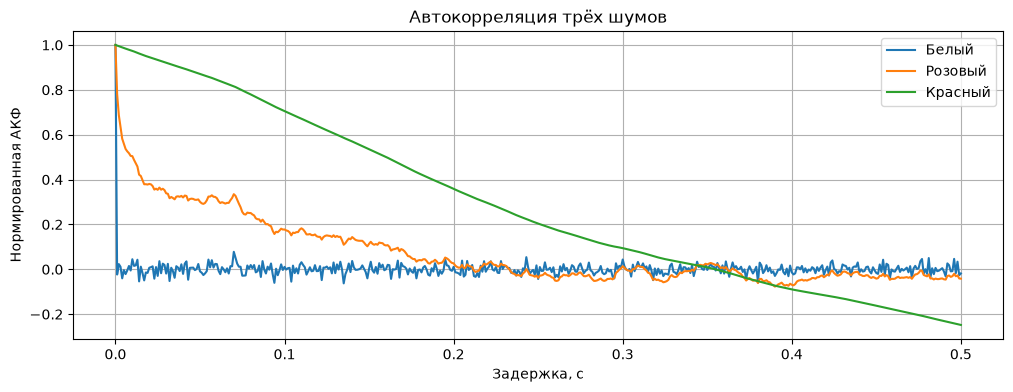

In [2]:
lags = np.arange(N)/fs
for name, x in noises.items():
    centered = x-x.mean()
    corr = np.correlate(centered, centered, mode='full')[N-1:]
    corr /= corr[0]
    plt.plot(lags[:501], corr[:501], label=name)
plt.xlabel('Задержка, с')
plt.ylabel('Нормированная АКФ')
plt.title('Автокорреляция трёх шумов')
plt.legend()
plt.show()

**Вопрос:** Сравнив АКФ и временную развёртку для разных видов шума, сделайте вывод о том, как форма АКФ связана с гладкостью сигнала.


Чем плавнее выглядит сигнал, тем медленнее у него падает АКФ. У белого шума соседние отсчёты почти не связаны, поэтому после нуля АКФ быстро падает. У розового связь держится дольше, у красного — ещё дольше. 

## Задание 3. Оценка спектральной плотности мощности (СПМ). Периодограмма и метод Уэлча
Для каждого типа шума вычислите:
- Периодограмму с помощью `scipy.signal.periodogram`.
- Оценку СПМ методом Уэлча с помощью `scipy.signal.welch` с параметрами `nperseg=256`, `noverlap=128`, окно Ханна.

Постройте на одном графике (для каждого шума отдельно) периодограмму и оценку Уэлча в двойном логарифмическом масштабе по оси Y (используйте `plt.loglog`).


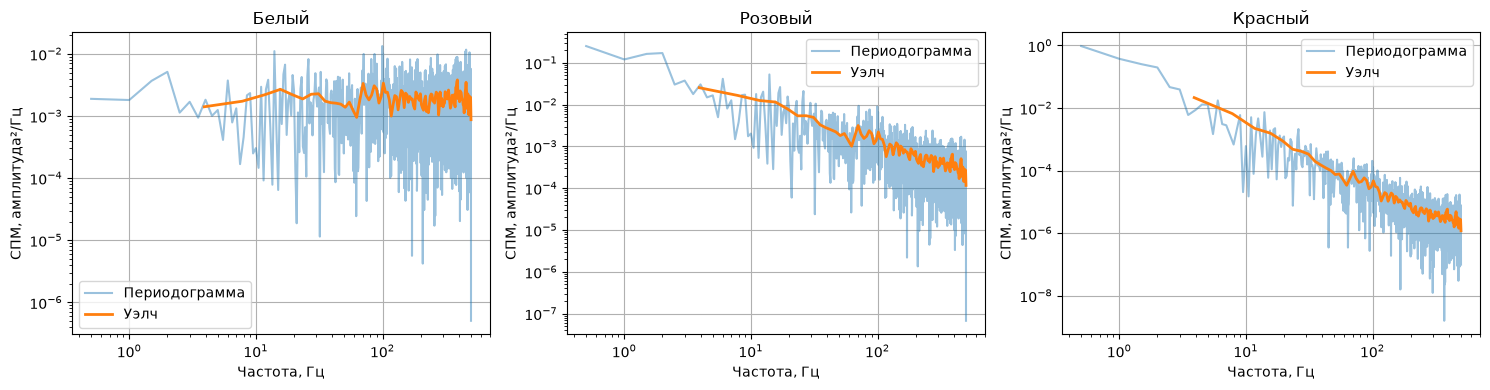

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, x) in zip(axes, noises.items()):
    fp, pp = signal.periodogram(x, fs=fs, scaling='density')
    fw, pw = signal.welch(x, fs=fs, window='hann', nperseg=256, noverlap=128,
                          scaling='density')
    ax.loglog(fp[1:], pp[1:], alpha=.45, label='Периодограмма')
    ax.loglog(fw[1:], pw[1:], lw=2, label='Уэлч')
    ax.set(title=name, xlabel='Частота, Гц', ylabel='СПМ, амплитуда²/Гц')
    ax.legend()
plt.tight_layout()
plt.show()

**Вопрос:** Как выглядят зависимости СПМ от частоты у разных видов шума в двойном логарифмическом масштабе? Как они должны выглядеть теоретически?


У белого шума спектр примерно горизонтальный, у розового спадает как 1/f, у красного — примерно как 1/f². В двойном логарифмическом масштабе мы видим наклоны около 0, −1 и −2. Периодограмма зубчатая, а Уэлч сглаживает её усреднением. На самых низких частотах и около Найквиста совпадение с идеальной прямой хуже.

## Задание 4. Влияние длины сегмента в методе Уэлча
Для белого шума вычислите оценку СПМ методом Уэлча с разной длиной сегмента: `nperseg = 64, 128, 256, 512`. Используйте окно Ханна, перекрытие 50%. Постройте все четыре оценки на одном графике (логарифмическая шкала по Y).


Сегмент   Шаг частот, Гц   Число сегментов
     64           15.6250                 61
    128            7.8125                 30
    256            3.9062                 14
    512            1.9531                  6


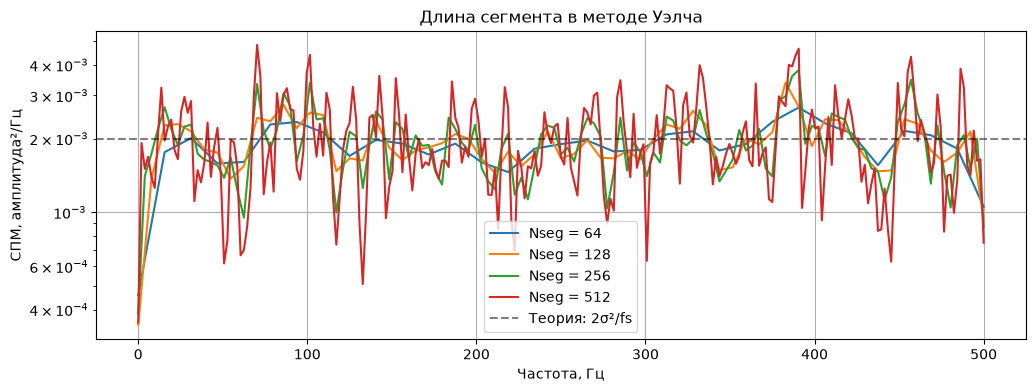

In [4]:
print('Сегмент   Шаг частот, Гц   Число сегментов')
for L in (64, 128, 256, 512):
    f_w, p_w = signal.welch(white, fs=fs, window='hann', nperseg=L, noverlap=L//2)
    plt.semilogy(f_w, p_w, label=f'Nseg = {L}')
    count = 1+(N-L)//(L//2)
    print(f'{L:7d} {fs/L:17.4f} {count:18d}')
plt.axhline(2/fs, color='k', ls='--', alpha=.5, label='Теория: 2σ²/fs')
plt.xlabel('Частота, Гц')
plt.ylabel('СПМ, амплитуда²/Гц')
plt.title('Длина сегмента в методе Уэлча')
plt.legend()
plt.show()

**Вопрос:** Как увеличение длины сегмента влияет на разрешение по частоте (ширину пиков) и гладкость оценки (дисперсию значений)?


Увелличивая сегмент — частотный шаг уменьшается, и близкие частоты различать легче. Но сегментов для усреднения становится меньше, поэтому линия сильнее колеблется. Получается, тут тоже приходится выбирать между разрешением и гладкостью.

## Задание 5. Влияние дисперсии шума на его характеристики
Для каждого вида шума вычислите и выведите на один график при разных значениях дисперсии (например, 0.1, 1, 10):
1. Временную реализацию.
2. АКФ.
3. СПМ.

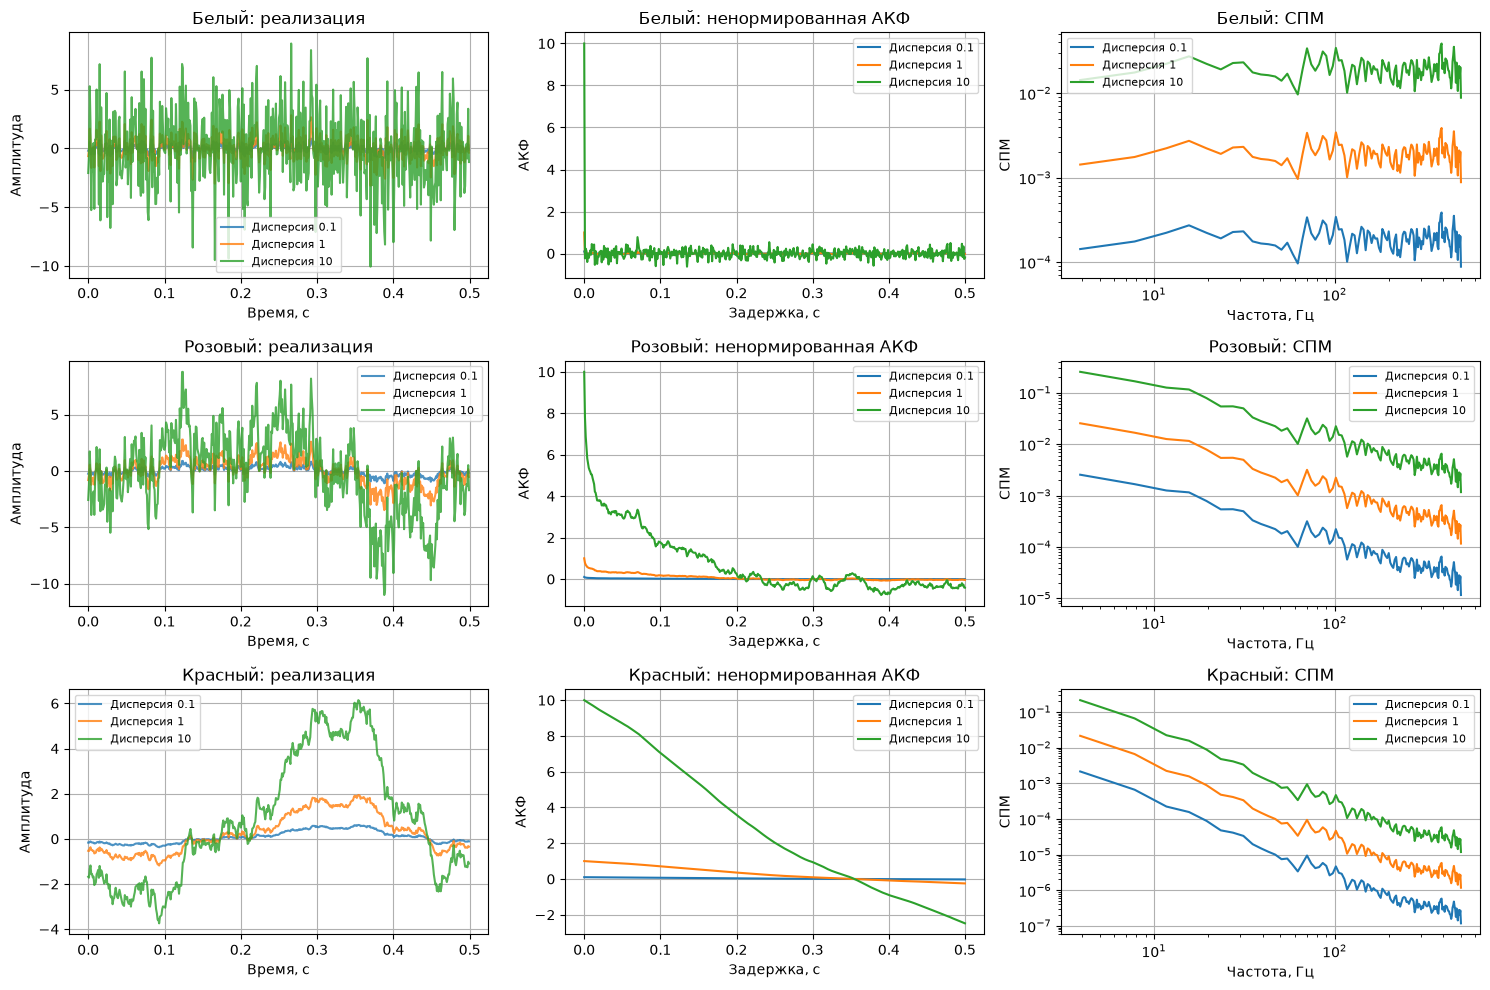

Для сравнения масштабируется одна и та же реализация, а не три разных случайных массива.


In [5]:
variances = (.1, 1, 10)
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for row, (name, base) in enumerate(noises.items()):
    base = (base-base.mean())/base.std()
    for variance in variances:
        x = np.sqrt(variance)*base
        acf = np.correlate(x, x, mode='full')[N-1:]/N
        fw, pw = signal.welch(x, fs=fs, nperseg=256, noverlap=128, window='hann')
        label = f'Дисперсия {variance:g}'
        axes[row, 0].plot(t[:500], x[:500], label=label, alpha=.8)
        axes[row, 1].plot(lags[:501], acf[:501], label=label)
        axes[row, 2].loglog(fw[1:], pw[1:], label=label)
    axes[row, 0].set(title=f'{name}: реализация', xlabel='Время, с', ylabel='Амплитуда')
    axes[row, 1].set(title=f'{name}: ненормированная АКФ', xlabel='Задержка, с', ylabel='АКФ')
    axes[row, 2].set(title=f'{name}: СПМ', xlabel='Частота, Гц', ylabel='СПМ')
    for ax in axes[row]: ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print('Для сравнения масштабируется одна и та же реализация, а не три разных случайных массива.')

**Вопрос:** Что меняется при изменении дисперсии в каждом случае?


Если увеличить дисперсию в 10 раз, амплитуда вырастет в √10 раз, а СПМ и ненормированная АКФ — в 10 раз. Сам характер шума у нас не меняется, графики просто растягиваются по высоте. Нормированная АКФ вообще осталась бы той же.

## Задание 6. Обнаружение гармонического сигнала на фоне шума. Спектральный анализ зашумлённой синусоиды
Сгенерируйте сигнал длительностью 2 секунды (fs=1000 Гц), состоящий из:
- синусоиды частотой 110 Гц с амплитудой 1,
- белого гауссова шума с дисперсией, обеспечивающей отношение сигнал/шум (SNR) = 10 дБ.

SNR (дБ) = $10 \log_{10}(P_{signal}/P_{noise})$.

1. Оцените СПМ с помощью метода Уэлча (выберите `nperseg` так, чтобы частота 110 Гц была хорошо разрешена). Определите частоту пика и сравните с истинной.
2. Повторите для других значений SNR ($0$ дБ, $-10$ дБ, $-20$ дБ и т. д.)


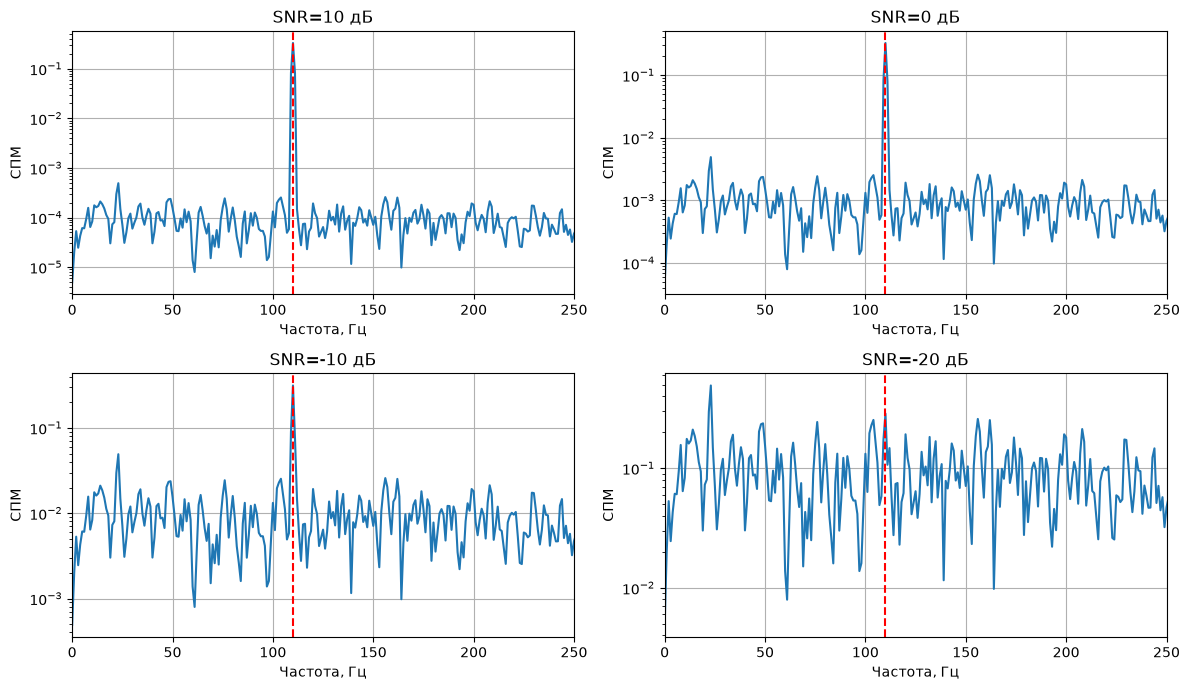

In [6]:
clean = np.sin(2*np.pi*110*t)
noise = rng.standard_normal(N)
noise /= np.sqrt(np.mean(noise**2))
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, snr_db in zip(axes.flat, [10, 0, -10, -20]):
    noisy = clean + noise*np.sqrt(np.mean(clean**2)/10**(snr_db/10))
    f, power = signal.welch(noisy, fs, nperseg=1000)
    ax.semilogy(f, power)
    ax.axvline(110, color='r', ls='--')
    ax.set(title=f'SNR={snr_db} дБ', xlabel='Частота, Гц', ylabel='СПМ', xlim=(0, 250))
plt.tight_layout()
plt.show()

**Вопрос:** Как меняется видимость пика на спектре при изменении SNR? При каком SNR пик ещё можно уверенно обнаружить визуально?


При 10 и 0 дБ пик видно хорошо. При −10 дБ я ещё могу выделить его на фоне, а при −20 дБ уверенности уже мало. Это результат для нашей короткой записи, а не общий предел: длинная запись и усреднение могут помочь.

## Задание 7. Разрешение двух близких частот
Сгенерируйте сигнал, содержащий две синусоиды с частотами 100 и 110 Гц, равными амплитудами 1, и белый шум с дисперсией 0.1. Длительность сигнала 1 секунда, fs=1000 Гц. Используйте метод Уэлча с разными длинами сегмента: 128, 256, 512. Постройте оценки СПМ для каждого случая.


Nseg=128: шаг исходной сетки 7.812 Гц, примерная ширина по Ханну 2fs/Nseg=15.625 Гц
Nseg=256: шаг исходной сетки 3.906 Гц, примерная ширина по Ханну 2fs/Nseg=7.812 Гц
Nseg=512: шаг исходной сетки 1.953 Гц, примерная ширина по Ханну 2fs/Nseg=3.906 Гц


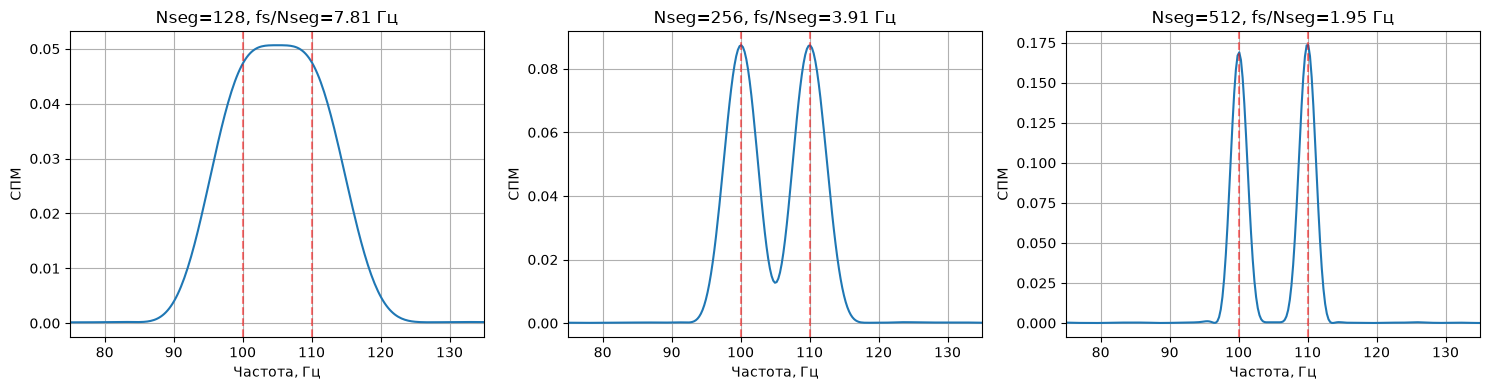

nfft=4096 лишь делает линии плавнее; реальное разрешение задаёт длина сегмента.


In [7]:
fs = 1000
t_two = np.arange(fs)/fs
rng_two = np.random.default_rng(41)
x_two = (np.sin(2*np.pi*100*t_two) + np.sin(2*np.pi*110*t_two)
         + np.sqrt(.1)*rng_two.standard_normal(fs))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, L in zip(axes, (128, 256, 512)):
    fw, pw = signal.welch(x_two, fs=fs, window='hann', nperseg=L, noverlap=L//2,
                          nfft=4096)
    ax.plot(fw, pw)
    ax.axvline(100, color='r', ls='--', alpha=.5)
    ax.axvline(110, color='r', ls='--', alpha=.5)
    ax.set(title=f'Nseg={L}, fs/Nseg={fs/L:.2f} Гц', xlim=(75, 135),
           xlabel='Частота, Гц', ylabel='СПМ')
    print(f'Nseg={L}: шаг исходной сетки {fs/L:.3f} Гц, '
          f'примерная ширина по Ханну 2fs/Nseg={2*fs/L:.3f} Гц')
plt.tight_layout()
plt.show()
print('nfft=4096 лишь делает линии плавнее; реальное разрешение задаёт длина сегмента.')

**Вопрос:** При какой длине сегмента удаётся разделить две частоты? Сравните с грубой теоретической оценкой частотного разрешения $\Delta f \approx f_s / N_{seg}$.


При 128 отсчётах у меня один широкий бугор. При 256 два пика уже видны, при 512 разделяются лучше. Оценка fs/Nseg даёт 7,81, 3,91 и 1,95 Гц, но для окна Ханна надо учитывать ещё ширину главного лепестка, примерно 2fs/Nseg. Дополнение нулями делает картинку плавнее, а сами частоты лучше не разделяет.

## Общий вывод

Разные шумы отличаются не только тем, насколько сильно колеблется сигнал, но и тем, какие частоты в нём преобладают. АКФ и СПМ показали это с двух сторон. Метод Уэлча оказался удобнее обычной периодограммы для общей картины, но длину окна всё равно нужно выбирать под задачу. Больше всего удивило, что синусоиду можно увидеть на спектре даже тогда, когда на временном графике она почти пропала в шуме.